# Climate Variability and Crop Production Stability
**Research question:** Is increasing temperature and precipitation variability associated with greater year-to-year instability in crop production? Which crops are most sensitive?

**Data:** FAOSTAT (yield, production, harvested area: rice, wheat, maize) and ERA5-Land monthly (2 m temperature, total precipitation) for India, China, USA, Brazil, Australia, 2000-2023.

**Notebook map**
0. Setup  1. Load FAOSTAT  2. Process ERA5-Land  3. ERA5 2023 rainfall check  4. Exploratory plots
5. Detrending and instability  6. Cross-country association  7. **Step 4: Is variability increasing? (4 sub-periods + rolling SD)**
8. **Year-level climate sensitivity (core analysis)**  9. **Step 7: Extreme years**  10. **Step 8: Climate-region comparison**
11. Summary of findings  12. Limitations

**Folder layout expected** (notebook sits next to `datasets/`):
```
datasets/maize_faostat.csv, rice_faostat.csv, wheat_faostat.csv
datasets/era5_india/*.nc, era5_china/*.nc, era5_usa/*.nc, era5_brazil/*.nc, era5_australia/*.nc
(optional) datasets/boundaries/ne_10m_admin_0_countries.shp   <- for masking ERA5 to country borders
```

## 0. Setup and configuration

In [1]:
import os, glob, warnings
import numpy as np, pandas as pd
import matplotlib.pyplot as plt, seaborn as sns
import xarray as xr
from scipy import stats
import statsmodels.api as sm, statsmodels.formula.api as smf
warnings.filterwarnings('ignore')
sns.set_theme(style='whitegrid', context='notebook')
pd.set_option('display.width', 200); pd.set_option('display.max_columns', 30)

DATA_DIR = 'datasets'
OUT_DIR  = 'outputs'
os.makedirs(f'{OUT_DIR}/figures', exist_ok=True); os.makedirs(f'{OUT_DIR}/tables', exist_ok=True)

COUNTRIES = {'India':'era5_india', 'China':'era5_china', 'United States of America':'era5_usa',
             'Brazil':'era5_brazil', 'Australia':'era5_australia'}
SHORT  = {'United States of America':'USA'}
CROPS  = ['Rice','Wheat','Maize']
CROP_COLORS = {'Rice':'#4C9F70', 'Wheat':'#1F4D3A', 'Maize':'#D98E04'}

START, END = 2000, 2022          # analysis window. 2023 is excluded from climate analysis (see section 3)
PERIODS = [(2000,2005),(2006,2011),(2012,2017),(2018,2022)]   # 4 sub-periods for Step 4
ROLL = 8                          # rolling window (years)
REUSE_CACHE = True                # reuse saved ERA5 annual/monthly tables if they exist (delete outputs/tables/climate_*.csv to recompute)

SHAPEFILE_CANDIDATES = [f'{DATA_DIR}/boundaries/ne_10m_admin_0_countries.shp',
                        'boundaries/ne_10m_admin_0_countries.shp',
                        '../data/raw/boundaries/ne_10m_admin_0_countries.shp']

def short(c): return SHORT.get(c, c)
def save(name):
    plt.tight_layout(); plt.savefig(f'{OUT_DIR}/figures/{name}.png', dpi=150, bbox_inches='tight'); plt.show()
print('Setup done')

Setup done


## 1. Load FAOSTAT
Each CSV is in long format (`Element` = Yield / Production / Area harvested). We pivot to one row per country-crop-year.

In [2]:
files = {'Rice':'rice_faostat.csv', 'Wheat':'wheat_faostat.csv', 'Maize':'maize_faostat.csv'}
raw = pd.concat([pd.read_csv(f'{DATA_DIR}/{fn}').assign(Crop=crop) for crop, fn in files.items()], ignore_index=True)
print('Raw rows:', len(raw)); print('FAOSTAT flags:\n', raw['Flag'].value_counts())
fao = (raw.pivot_table(index=['Area','Crop','Year'], columns='Element', values='Value').reset_index()
          .rename(columns={'Area':'Country','Area harvested':'AreaHarvested'}))
fao.columns.name = None
fao = fao[(fao.Year>=2000)&(fao.Year<=2023)].sort_values(['Country','Crop','Year']).reset_index(drop=True)
print('\nPivoted:', fao.shape, '| countries:', fao.Country.nunique(), '| crops:', fao.Crop.nunique())
print('Years per series:', fao.groupby(['Country','Crop']).size().unique())
assert (fao[['Yield','Production','AreaHarvested']]>0).all().all(), 'zeros/negatives found: cannot take logs'
est = raw[raw.Flag!='A'][['Area','Crop','Year','Element','Flag','Flag Description']]
print('\nNon-official (estimated/imputed) values:'); display(est)
fao.head()

Raw rows: 1080
FAOSTAT flags:
 Flag
A    1076
E       4
Name: count, dtype: int64

Pivoted: (360, 6) | countries: 5 | crops: 3
Years per series: [24]

Non-official (estimated/imputed) values:


,Area,Crop,Year,Element,Flag,Flag Description
868,China,Maize,2001,Yield,E,Estimated value
869,China,Maize,2001,Production,E,Estimated value
871,China,Maize,2002,Yield,E,Estimated value
872,China,Maize,2002,Production,E,Estimated value


,Country,Crop,Year,AreaHarvested,Production,Yield
0,Australia,Maize,2000,82262.0,406043.0,4936.0
1,Australia,Maize,2001,74225.0,344934.0,4647.1
2,Australia,Maize,2002,82626.0,453853.0,5492.9
3,Australia,Maize,2003,49552.0,310049.0,6257.0
4,Australia,Maize,2004,70126.0,394990.0,5632.6


## 2. Process ERA5-Land (monthly) to country-level annual climate
Steps: open each country's NetCDF -> K to degC and m/day to mm/month (x1000 x days in month) -> mask to the country border (if the Natural Earth shapefile is available; otherwise the download bounding box is used and a warning is printed) -> **area-weighted (cos latitude) spatial mean** -> annual temperature (mean of 12 months) and annual rainfall (sum of 12 months).

In [3]:
cgdf = None
try:
    import geopandas as gpd
    for p in SHAPEFILE_CANDIDATES:
        if os.path.exists(p):
            cgdf = gpd.read_file(p); print('Using country boundaries from:', p); break
except ImportError:
    pass
if cgdf is None:
    print('WARNING: no country shapefile found -> using the full ERA5 download box for each country (includes some neighbouring land/sea).')

def process_country(country, folder):
    nc = sorted(glob.glob(f'{DATA_DIR}/{folder}/*.nc'))
    if not nc: raise FileNotFoundError(f'No .nc file in {DATA_DIR}/{folder}')
    ds = xr.open_dataset(nc[0])
    t = ds['t2m'] - 273.15
    p = ds['tp']
    if cgdf is not None:
        from shapely import contains_xy
        col = 'ADMIN' if 'ADMIN' in cgdf.columns else 'NAME'
        geom = cgdf[cgdf[col]==country].geometry.iloc[0]
        lon2d, lat2d = np.meshgrid(ds.longitude.values, ds.latitude.values)
        mask = xr.DataArray(contains_xy(geom, lon2d, lat2d), dims=['latitude','longitude'],
                            coords={'latitude':ds.latitude, 'longitude':ds.longitude})
        t, p = t.where(mask), p.where(mask)
    w = np.cos(np.deg2rad(ds.latitude))
    tm = t.weighted(w).mean(dim=['latitude','longitude'])
    pm = p.weighted(w).mean(dim=['latitude','longitude'])
    m = pd.DataFrame({'date':pd.to_datetime(ds['valid_time'].values),
                      'temperature_C':tm.values,
                      'precipitation_mm':pm.values*1000*pd.to_datetime(ds['valid_time'].values).days_in_month})
    m['country']=country; m['year']=m.date.dt.year; m['month']=m.date.dt.month
    return m

mpath, apath = f'{OUT_DIR}/tables/climate_monthly.csv', f'{OUT_DIR}/tables/climate_annual.csv'
if REUSE_CACHE and os.path.exists(mpath):
    clim_m = pd.read_csv(mpath, parse_dates=['date']); print('Loaded cached monthly climate')
else:
    clim_m = pd.concat([process_country(c,f) for c,f in COUNTRIES.items()], ignore_index=True)
    clim_m.to_csv(mpath, index=False)
chk = clim_m.groupby(['country','year']).size()
print('All country-years have 12 months:', (chk==12).all())
clim_a = (clim_m.groupby(['country','year']).agg(temperature_C=('temperature_C','mean'), precipitation_mm=('precipitation_mm','sum')).reset_index())
clim_a.to_csv(apath, index=False)
clim_a.pivot(index='year', columns='country', values='precipitation_mm').round(0).tail(6)

Using country boundaries from: datasets/boundaries/ne_10m_admin_0_countries.shp
All country-years have 12 months: True


country,Australia,Brazil,China,India,United States of America
year,,,,,
2018,364.0,1800.0,795.0,1175.0,917.0
2019,240.0,1670.0,767.0,1439.0,927.0
2020,465.0,1667.0,829.0,1390.0,790.0
2021,473.0,1771.0,820.0,1299.0,812.0
2022,452.0,1405.0,690.0,1181.0,644.0
2023,241.0,649.0,409.0,652.0,383.0


## 3. Data-quality check: ERA5 2023 rainfall
Previous notebooks found that ERA5 annual rainfall in **2023 is roughly half of normal in every country at the same time**, and for India it disagrees with CHIRPS (CHIRPS 1095 mm vs ERA5 652 mm). A simultaneous ~50% drop in all five countries is not a plausible real climate signal, so it is treated as a **data artefact**. Including it would inflate every rainfall-variability number. **Decision: the analysis window is 2000-2022.**

,mean_monthly_ratio,months_below_50pct,annual_2023_vs_normal
country,,,
Australia,0.49,5,0.54
Brazil,0.34,12,0.37
China,0.50,5,0.52
India,0.55,5,0.52
United States of America,0.49,7,0.48


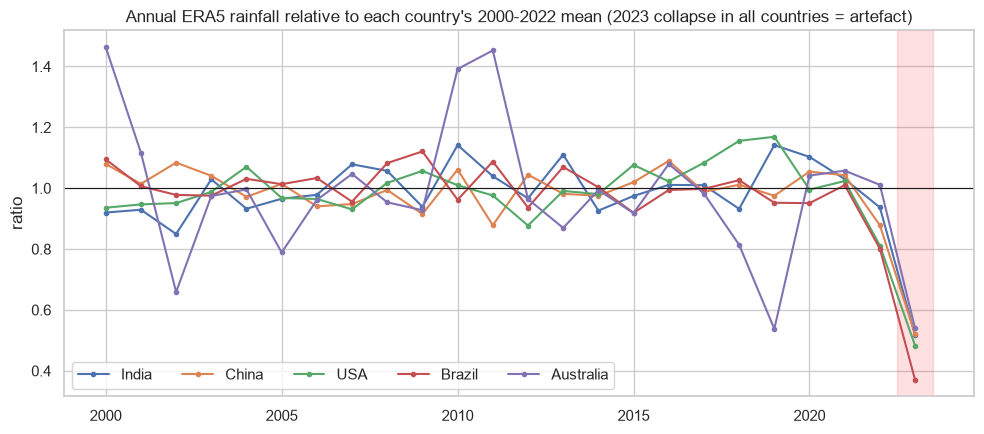

In [4]:
base = clim_m[clim_m.year<=2022].groupby(['country','month']).precipitation_mm.mean().rename('normal').reset_index()
d23 = clim_m[clim_m.year==2023].merge(base, on=['country','month']); d23['ratio'] = d23.precipitation_mm/d23.normal
diag = d23.groupby('country').agg(mean_monthly_ratio=('ratio','mean'), months_below_50pct=('ratio', lambda r:(r<0.5).sum()))
ann_ratio = (clim_a[clim_a.year==2023].set_index('country').precipitation_mm / clim_a[clim_a.year<=2022].groupby('country').precipitation_mm.mean()).rename('annual_2023_vs_normal')
display(diag.join(ann_ratio).round(2))

fig, ax = plt.subplots(figsize=(10,4.5))
for c in COUNTRIES:
    d = clim_a[clim_a.country==c]; ax.plot(d.year, d.precipitation_mm/d[d.year<=2022].precipitation_mm.mean(), marker='o', ms=3, label=short(c))
ax.axvspan(2022.5, 2023.5, color='red', alpha=0.12); ax.axhline(1, color='k', lw=0.8)
ax.set_title('Annual ERA5 rainfall relative to each country\'s 2000-2022 mean (2023 collapse in all countries = artefact)'); ax.set_ylabel('ratio'); ax.legend(ncol=5)
save('01_era5_2023_check')

## 4. Exploratory plots and descriptive statistics

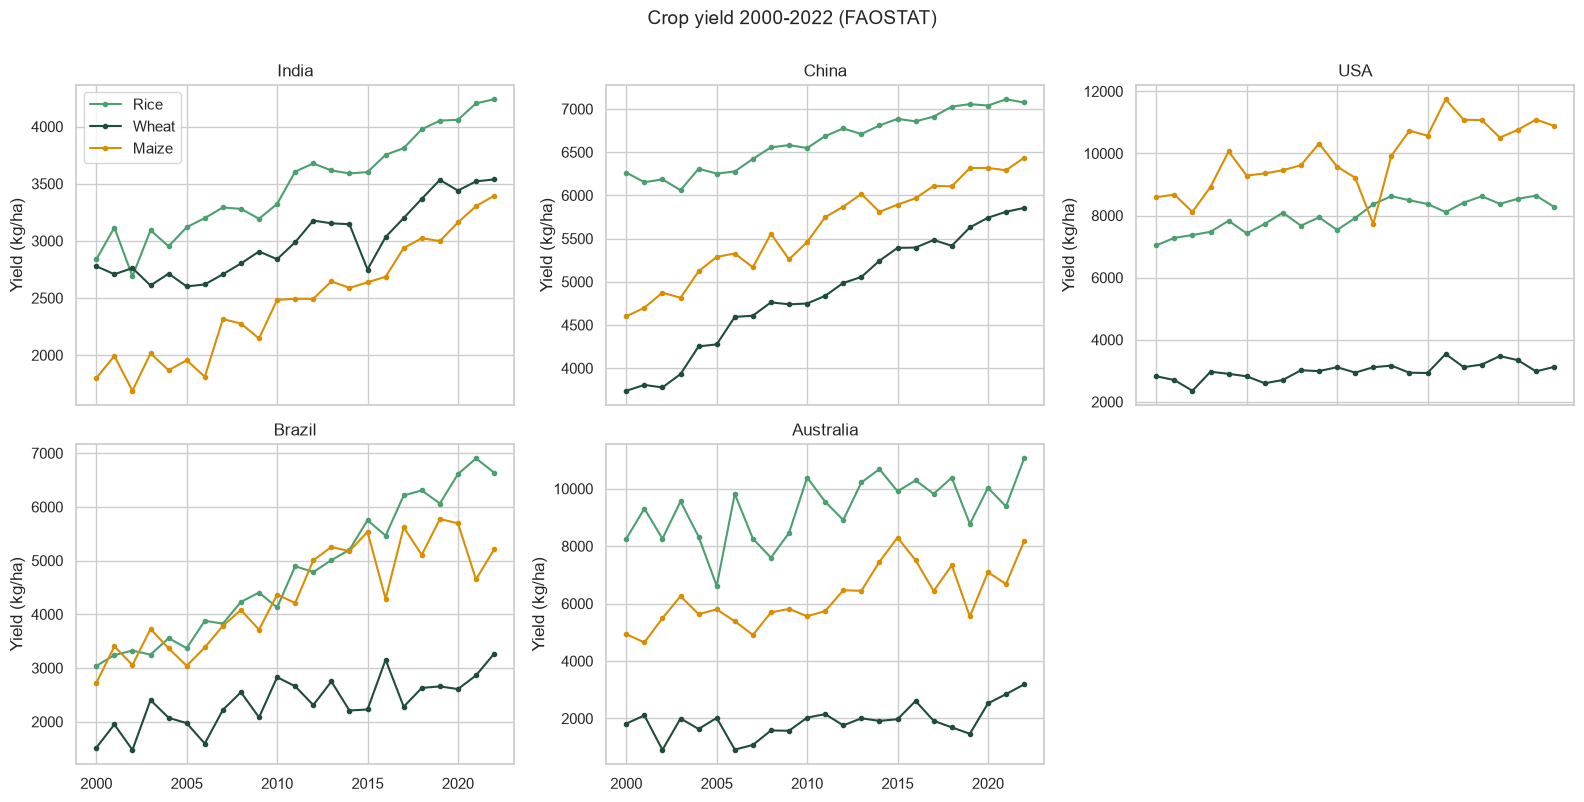

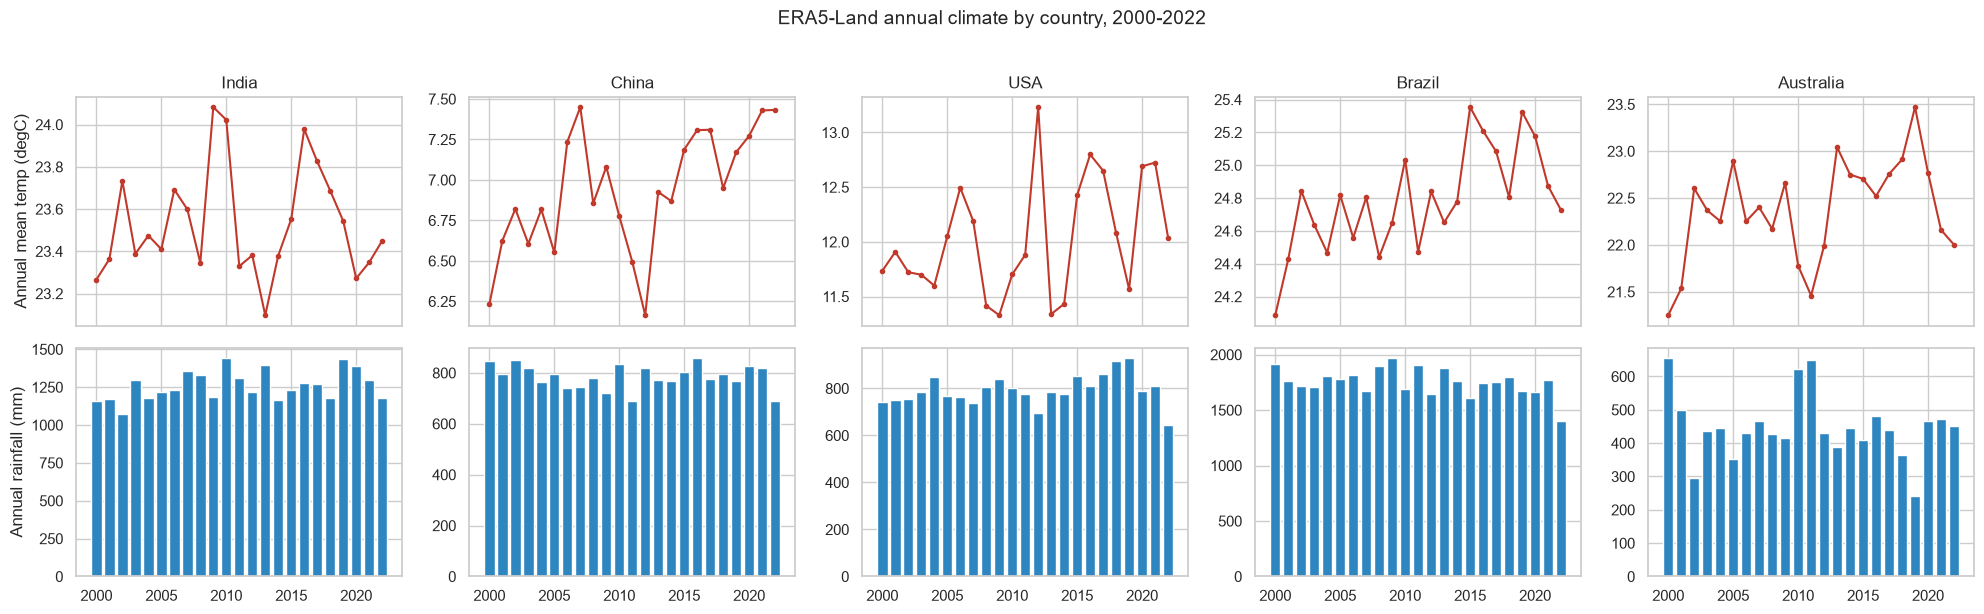

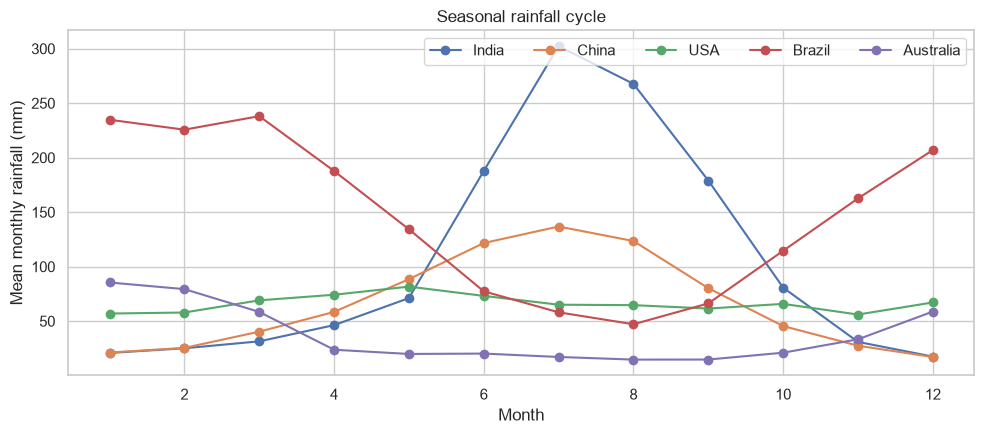

mean_yield  sd_yield    mean_prod   mean_area  raw_yield_CV_%  yield_change_%_2000_2022
Country                  Crop                                                                                          
Australia                Maize      6230.9    1019.2     381526.8     62179.7            16.4                      65.6
                         Rice       9298.0    1090.8     607290.5     65091.6            11.7                      33.9
                         Wheat      1901.3     554.9   23611292.3  12342260.7            29.2                      75.1
Brazil                   Maize      4354.9     959.2   65870072.1  14693823.1            22.0                      91.6
                         Rice       4786.5    1260.3   11616569.3   2591626.5            26.3                     118.5
                         Wheat      2359.7     479.5    5352269.8   2223603.7            20.3                     115.5
China                    Maize      5610.7     561.3  195174286.7  34110084.7            10.0                      39.9
                         Rice       6632.9     337.8  198621064.8  29909141.1             5.1                      13.0
                         Wheat      4873.0     674.8  116563127.5  23918681.1            13.8                      56.6
India                    Maize      2466.0     507.9   21280644.3   8430862.3            20.6                      88.7
                         Rice       3490.6     440.9  153215097.1  43815318.9            12.6                      49.4
                         Wheat      2995.5     319.2   86421019.2  28699783.0            10.7                      27.3
United States of America Maize      9883.0    1057.7  318937581.7  32156562.2            10.7                      26.7
                         Rice       8006.9     489.5    9291074.8   1166051.7             6.1                      17.6
                         Wheat      2994.8     269.3   55187135.0  18523718.5             9.0                      10.7

In [5]:
cl = clim_a[(clim_a.year>=START)&(clim_a.year<=END)].rename(columns={'country':'Country','year':'Year'})
fao_w = fao[(fao.Year>=START)&(fao.Year<=END)].copy()

# 4.1 Yield time series
fig, axes = plt.subplots(2,3, figsize=(16,8), sharex=True); axes=axes.ravel()
for ax,c in zip(axes, COUNTRIES):
    for cr in CROPS:
        d = fao_w[(fao_w.Country==c)&(fao_w.Crop==cr)]; ax.plot(d.Year, d.Yield, marker='o', ms=3, color=CROP_COLORS[cr], label=cr)
    ax.set_title(short(c)); ax.set_ylabel('Yield (kg/ha)')
axes[0].legend(); axes[-1].axis('off'); fig.suptitle('Crop yield 2000-2022 (FAOSTAT)', y=1.0, fontsize=14)
save('02_yield_series')

# 4.2 Climate time series
fig, axes = plt.subplots(2,5, figsize=(20,6), sharex=True)
for j,c in enumerate(COUNTRIES):
    d = cl[cl.Country==c]
    axes[0,j].plot(d.Year, d.temperature_C, color='#C0392B', marker='o', ms=3); axes[0,j].set_title(short(c))
    axes[1,j].bar(d.Year, d.precipitation_mm, color='#2E86C1')
axes[0,0].set_ylabel('Annual mean temp (degC)'); axes[1,0].set_ylabel('Annual rainfall (mm)')
fig.suptitle('ERA5-Land annual climate by country, 2000-2022', y=1.02, fontsize=14)
save('03_climate_series')

# 4.3 Seasonal rainfall cycle (shows why climates are 'contrasting')
fig, ax = plt.subplots(figsize=(10,4.5))
sc = clim_m[clim_m.year<=END].groupby(['country','month']).precipitation_mm.mean().reset_index()
for c in COUNTRIES: d=sc[sc.country==c]; ax.plot(d.month, d.precipitation_mm, marker='o', label=short(c))
ax.set_xlabel('Month'); ax.set_ylabel('Mean monthly rainfall (mm)'); ax.set_title('Seasonal rainfall cycle'); ax.legend(ncol=5)
save('04_seasonal_rainfall')

# 4.4 Descriptive table
desc = fao_w.groupby(['Country','Crop']).agg(mean_yield=('Yield','mean'), sd_yield=('Yield','std'), mean_prod=('Production','mean'),
                                              mean_area=('AreaHarvested','mean')).round(1)
desc['raw_yield_CV_%'] = (desc.sd_yield/desc.mean_yield*100).round(1)
first = fao_w[fao_w.Year==START].set_index(['Country','Crop']).Yield; last = fao_w[fao_w.Year==END].set_index(['Country','Crop']).Yield
desc['yield_change_%_2000_2022'] = ((last/first-1)*100).round(1)
desc.to_csv(f'{OUT_DIR}/tables/descriptive_faostat.csv'); display(desc)

## 5. Detrending and instability metrics
**Why detrend?** Yields rise over time because of technology, irrigation and breeding. A raw standard deviation or CV mostly measures that upward trend, not instability caused by weather. 

**Method (applied to each country-crop series):**
1. Take logs: `log(Yield)`. Logs make deviations relative (a 10% shock is comparable in Brazil and the USA) and make growth roughly linear.
2. Fit a linear trend on year. The slope x100 is the average annual growth rate (%/yr).
3. The **residual** is the year's shock: a residual of -0.15 means about 15% below trend.
4. **Instability = standard deviation of the residuals.** The same is done for Production and Area harvested. Since `Production = Yield x Area`, `log P = log Y + log A`, so production instability can be **decomposed** into a yield part (weather/management) and an area part (farmer decisions, water allocation).

**Climate variability:** temperature = SD of detrended annual mean temperature (removes warming trend); rainfall = coefficient of variation (SD / mean, %). Climate anomalies are standardised (z-scores) per country so that effects are comparable across countries.

In [6]:
def detrend(y, x):
    b = np.polyfit(x, y, 1); return y - np.polyval(b, x), b[0]

rows = []
for (c,cr), g in fao_w.groupby(['Country','Crop']):
    g = g.sort_values('Year').copy(); x = g.Year.values
    g['ly_res'], sy = detrend(np.log(g.Yield.values), x)
    g['lp_res'], sp = detrend(np.log(g.Production.values), x)
    g['la_res'], sa = detrend(np.log(g.AreaHarvested.values), x)
    g['yield_growth_pct_yr'], g['prod_growth_pct_yr'] = sy*100, sp*100
    rows.append(g)
panel = pd.concat(rows, ignore_index=True)

# climate anomalies (z-scores per country)
cc = []
for c,g in cl.groupby('Country'):
    g = g.sort_values('Year').copy()
    g['temp_res'], tslope = detrend(g.temperature_C.values, g.Year.values)
    g['temp_z'] = g.temp_res/g.temp_res.std(ddof=1)
    g['rain_z'] = (g.precipitation_mm-g.precipitation_mm.mean())/g.precipitation_mm.std(ddof=1)
    g['temp_trend_C_per_decade'] = tslope*10
    cc.append(g)
cl2 = pd.concat(cc, ignore_index=True)
panel = panel.merge(cl2[['Country','Year','temperature_C','precipitation_mm','temp_res','temp_z','rain_z']], on=['Country','Year'])
panel['label'] = panel.Country.map(short)
panel['series'] = panel.label + ' ' + panel.Crop

# climate variability table
clim_var = cl2.groupby('Country').agg(mean_temp_C=('temperature_C','mean'), temp_SD_detrended=('temp_res', lambda s:s.std(ddof=1)),
            temp_trend_C_per_decade=('temp_trend_C_per_decade','first'), mean_rain_mm=('precipitation_mm','mean'),
            rain_SD_mm=('precipitation_mm', lambda s:s.std(ddof=1))).reset_index()
clim_var['rain_CV_%'] = clim_var.rain_SD_mm/clim_var.mean_rain_mm*100
clim_var['label'] = clim_var.Country.map(short)
clim_var.round(3).to_csv(f'{OUT_DIR}/tables/climate_variability.csv', index=False)
print('Climate variability by country (2000-2022)'); display(clim_var.drop(columns='label').round(3))

# instability table
inst = panel.groupby(['Country','Crop']).agg(
    yield_instability=('ly_res', lambda s:s.std(ddof=1)), prod_instability=('lp_res', lambda s:s.std(ddof=1)),
    area_instability=('la_res', lambda s:s.std(ddof=1)), yield_growth_pct_yr=('yield_growth_pct_yr','first'),
    yield_mean=('Yield','mean'), yield_sd_raw=('Yield', lambda s:s.std(ddof=1))).reset_index()
inst['raw_yield_CV_%'] = inst.yield_sd_raw/inst.yield_mean*100
vy = panel.groupby(['Country','Crop']).ly_res.var(ddof=1).values; va = panel.groupby(['Country','Crop']).la_res.var(ddof=1).values
vp = panel.groupby(['Country','Crop']).lp_res.var(ddof=1).values
inst['var_share_yield_%'] = vy/vp*100; inst['var_share_area_%'] = va/vp*100; inst['var_share_covariance_%'] = 100-inst['var_share_yield_%']-inst['var_share_area_%']
inst['label'] = inst.Country.map(short)
inst.drop(columns=['yield_sd_raw']).round(3).to_csv(f'{OUT_DIR}/tables/instability.csv', index=False)
print('\nInstability (SD of detrended log values)'); display(inst[['label','Crop','yield_instability','prod_instability','area_instability','yield_growth_pct_yr','raw_yield_CV_%']].round(3))

Climate variability by country (2000-2022)


,Country,mean_temp_C,temp_SD_detrended,temp_trend_C_per_decade,mean_rain_mm,rain_SD_mm,rain_CV_%
0,Australia,22.379,0.493,0.335,446.898,97.367,21.787
1,Brazil,24.785,0.239,0.299,1753.487,121.312,6.918
2,China,6.938,0.298,0.333,786.173,47.471,6.038
3,India,23.531,0.259,0.017,1260.801,98.941,7.847
4,United States of America,12.031,0.494,0.298,793.332,64.047,8.073



Instability (SD of detrended log values)


,label,Crop,yield_instability,prod_instability,area_instability,yield_growth_pct_yr,raw_yield_CV_%
0,Australia,Maize,0.106,0.184,0.158,1.771,16.357
1,Australia,Rice,0.101,1.168,1.119,1.035,11.732
2,Australia,Wheat,0.270,0.319,0.089,2.411,29.184
3,Brazil,Maize,0.106,0.124,0.060,2.988,22.026
4,Brazil,Rice,0.042,0.083,0.080,3.892,26.331
5,Brazil,Wheat,0.142,0.279,0.195,2.382,20.322
6,China,Maize,0.025,0.066,0.059,1.461,10.004
7,China,Rice,0.012,0.038,0.029,0.735,5.093
8,China,Wheat,0.029,0.049,0.041,2.065,13.847
9,India,Maize,0.055,0.062,0.031,2.961,20.595


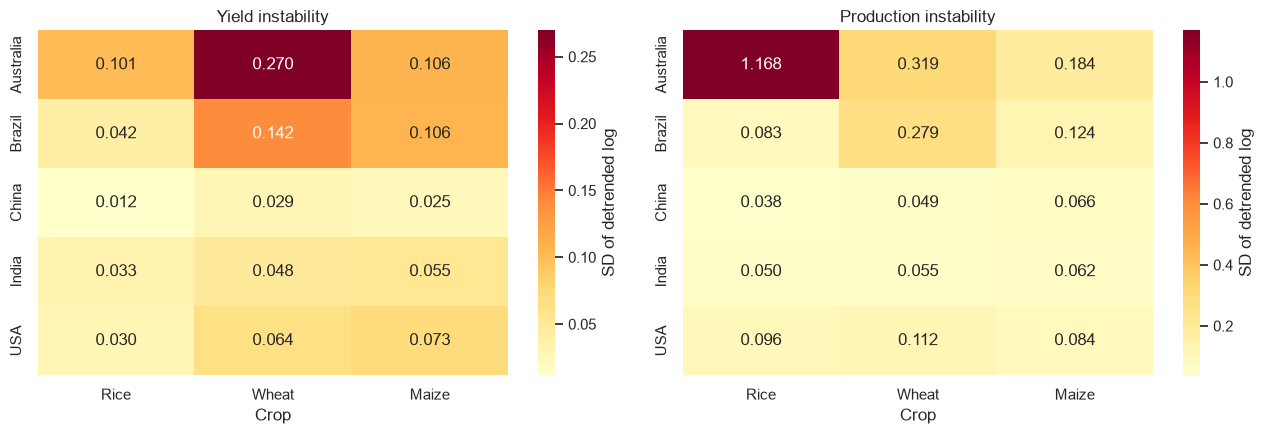

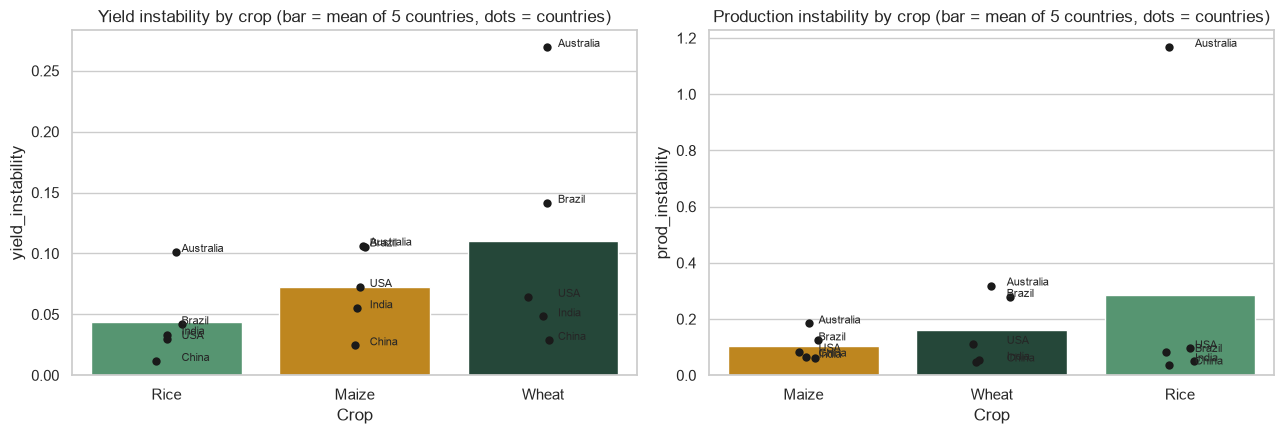

Mean instability by crop (low = stable)


,yield_instability,prod_instability,area_instability
Crop,,,
Rice,0.044,0.287,0.270
Maize,0.073,0.104,0.073
Wheat,0.111,0.163,0.085


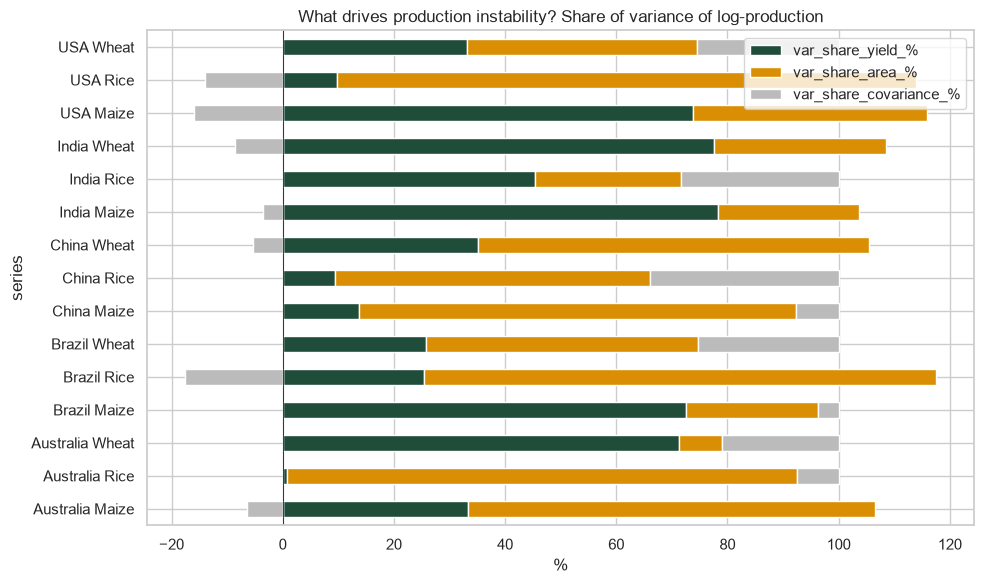

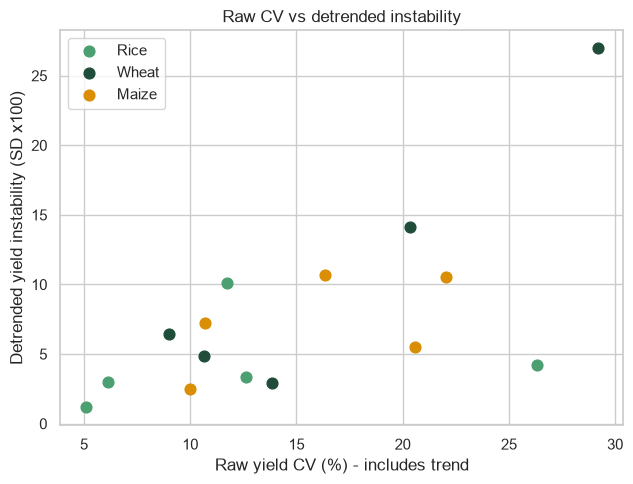

In [7]:
# 5.1 Heatmaps: yield and production instability
fig, axes = plt.subplots(1,2, figsize=(13,4.5))
for ax,col,t in zip(axes, ['yield_instability','prod_instability'], ['Yield instability','Production instability']):
    pv = inst.pivot(index='label', columns='Crop', values=col)[CROPS]
    sns.heatmap(pv, annot=True, fmt='.3f', cmap='YlOrRd', ax=ax, cbar_kws={'label':'SD of detrended log'}); ax.set_title(t); ax.set_ylabel('')
save('05_instability_heatmaps')

# 5.2 Crop ranking
fig, axes = plt.subplots(1,2, figsize=(13,4.5))
for ax,col,t in zip(axes, ['yield_instability','prod_instability'], ['Yield instability by crop','Production instability by crop']):
    order = inst.groupby('Crop')[col].mean().sort_values().index
    sns.barplot(data=inst, x='Crop', y=col, order=order, errorbar=None, palette=CROP_COLORS, ax=ax)
    sns.stripplot(data=inst, x='Crop', y=col, order=order, color='k', size=6, ax=ax)
    for _,r in inst.iterrows(): ax.text(list(order).index(r.Crop)+0.08, r[col], r.label, fontsize=8)
    ax.set_title(t+' (bar = mean of 5 countries, dots = countries)')
save('06_crop_ranking')
crop_rank = inst.groupby('Crop')[['yield_instability','prod_instability','area_instability']].mean().sort_values('yield_instability')
print('Mean instability by crop (low = stable)'); display(crop_rank.round(3))

# 5.3 Production instability decomposition
dd = inst.assign(series=inst.label+' '+inst.Crop).set_index('series')[['var_share_yield_%','var_share_area_%','var_share_covariance_%']]
dd.plot(kind='barh', stacked=True, figsize=(10,6), color=['#1F4D3A','#D98E04','#BBBBBB']); plt.axvline(0,color='k',lw=0.6)
plt.title('What drives production instability? Share of variance of log-production'); plt.xlabel('%'); save('07_production_decomposition')

# 5.4 Raw CV vs detrended instability (why detrending matters)
fig, ax = plt.subplots(figsize=(6.5,5))
for cr in CROPS:
    d = inst[inst.Crop==cr]; ax.scatter(d['raw_yield_CV_%'], d.yield_instability*100, color=CROP_COLORS[cr], label=cr, s=60)
ax.set_xlabel('Raw yield CV (%) - includes trend'); ax.set_ylabel('Detrended yield instability (SD x100)'); ax.legend(); ax.set_title('Raw CV vs detrended instability')
save('08_rawcv_vs_detrended')

**How to read the decomposition:** if the yield share is large, production swings come mostly from yield (where weather acts directly). If the area share is large (e.g. Australian rice), production swings come mostly from farmers changing planted area, often because of water availability - an indirect climate effect.

## 6. Cross-country association (supporting evidence)
Does a country with more variable rainfall/temperature have more unstable yields? We correlate the climate-variability metric of each country with each country-crop yield instability. 

**Caveat:** there are 15 points, but only **5 independent climate values** (the 3 crops share a country's climate). We therefore also report Spearman (rank) correlations, the correlation without Australia (a possible outlier), and a 5-point country-level version. This is *indicative only*; the main evidence is the year-level analysis in section 8.

,sample,climate,n,pearson_r,pearson_p,spearman_rho,spearman_p
0,All 15 country-crop,rain_CV_%,15,0.668,0.007,0.622,0.013
1,Excluding Australia (12),rain_CV_%,12,0.185,0.564,0.453,0.139
2,Country level (5),rain_CV_%,5,0.874,0.052,0.700,0.188
3,All 15 country-crop,temp_SD_detrended,15,0.343,0.211,0.011,0.969
4,Excluding Australia (12),temp_SD_detrended,12,-0.135,0.677,-0.345,0.271
5,Country level (5),temp_SD_detrended,5,0.449,0.449,0.100,0.873


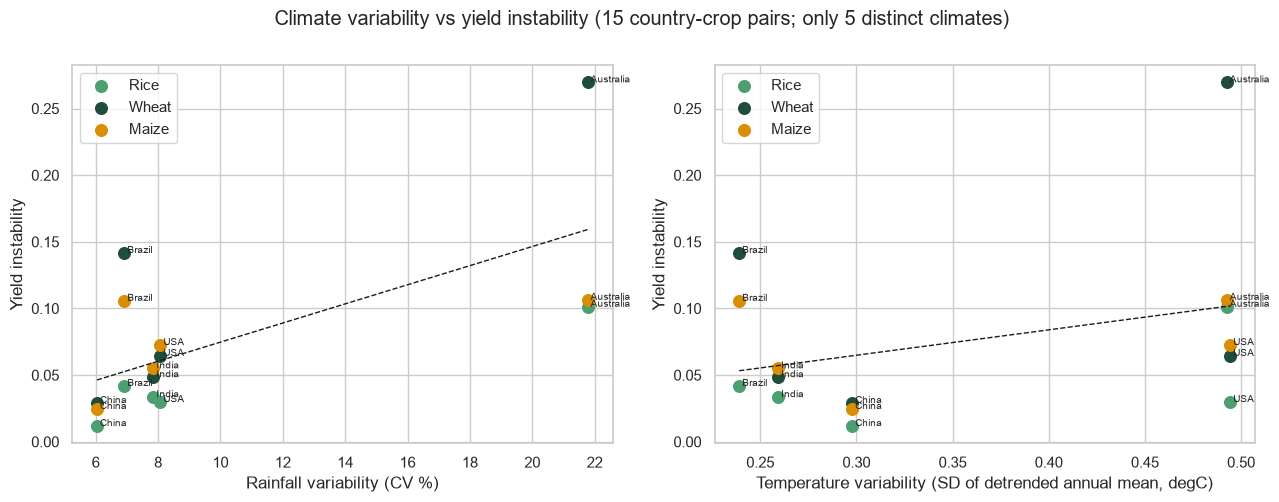

In [8]:
A = inst.merge(clim_var[['Country','temp_SD_detrended','rain_CV_%','mean_rain_mm','mean_temp_C']], on='Country')
def corr_row(d, xcol, ycol, name):
    r,p = stats.pearsonr(d[xcol], d[ycol]); rs,ps = stats.spearmanr(d[xcol], d[ycol])
    return dict(sample=name, climate=xcol, n=len(d), pearson_r=r, pearson_p=p, spearman_rho=rs, spearman_p=ps)
res = []
for xcol in ['rain_CV_%','temp_SD_detrended']:
    res += [corr_row(A, xcol,'yield_instability','All 15 country-crop'), corr_row(A[A.Country!='Australia'], xcol,'yield_instability','Excluding Australia (12)'),
            corr_row(A.groupby('Country',as_index=False).mean(numeric_only=True), xcol,'yield_instability','Country level (5)')]
corr_tab = pd.DataFrame(res).round(3); corr_tab.to_csv(f'{OUT_DIR}/tables/cross_country_correlations.csv', index=False); display(corr_tab)

fig, axes = plt.subplots(1,2, figsize=(13,5))
for ax,xcol,xl in zip(axes, ['rain_CV_%','temp_SD_detrended'], ['Rainfall variability (CV %)','Temperature variability (SD of detrended annual mean, degC)']):
    for cr in CROPS:
        d = A[A.Crop==cr]; ax.scatter(d[xcol], d.yield_instability, color=CROP_COLORS[cr], s=70, label=cr)
    for _,r in A.iterrows(): ax.text(r[xcol], r.yield_instability, ' '+r.label, fontsize=7)
    b = np.polyfit(A[xcol], A.yield_instability, 1); xs = np.linspace(A[xcol].min(), A[xcol].max(), 20); ax.plot(xs, np.polyval(b,xs), 'k--', lw=1)
    ax.set_xlabel(xl); ax.set_ylabel('Yield instability'); ax.legend()
fig.suptitle('Climate variability vs yield instability (15 country-crop pairs; only 5 distinct climates)', y=1.0)
save('09_cross_country_scatter')

## 7. Step 4 - Is variability increasing? (4 sub-periods + rolling SD)
The question says *increasing* variability, so we need a time dimension. Two complementary views:
- **Four sub-periods** (2000-05, 2006-11, 2012-17, 2018-22): the SD of the (full-period) detrended residuals within each block. For rainfall we use the SD of rainfall within each block divided by the country's full-period mean (a block CV).
- **Rolling 8-year SD**, plotted continuously.
- A simple trend test: regress the absolute residual on year; a positive slope means deviations are growing.

**Caution:** each block has only 5-6 years, so SDs are noisy. This is exploratory evidence of direction, not a significance claim.

period           2000-05  2006-11  2012-17  2018-22  first_half_mean  second_half_mean  ratio_2nd_to_1st
label     Crop                                                                                          
Australia Maize    0.087    0.050    0.103    0.133            0.068             0.118             1.725
          Rice     0.141    0.115    0.058    0.086            0.128             0.072             0.559
          Wheat    0.316    0.296    0.119    0.303            0.306             0.211             0.688
Brazil    Maize    0.105    0.058    0.111    0.113            0.082             0.112             1.372
          Rice     0.044    0.049    0.038    0.042            0.047             0.040             0.857
          Wheat    0.168    0.177    0.146    0.066            0.173             0.106             0.615
China     Maize    0.028    0.029    0.023    0.012            0.028             0.018             0.628
          Rice     0.018    0.011    0.007    0.009            0.015             0.008             0.549
          Wheat    0.028    0.022    0.010    0.010            0.025             0.010             0.392
India     Maize    0.073    0.083    0.029    0.016            0.078             0.023             0.289
          Rice     0.056    0.031    0.026    0.007            0.044             0.017             0.384
          Wheat    0.050    0.025    0.067    0.017            0.037             0.042             1.123
USA       Maize    0.061    0.045    0.129    0.027            0.053             0.078             1.481
          Rice     0.025    0.032    0.030    0.027            0.029             0.028             0.995
          Wheat    0.080    0.057    0.067    0.069            0.068             0.068             0.986

Series where yield variability rose (2nd half > 1st half): 4 of 15


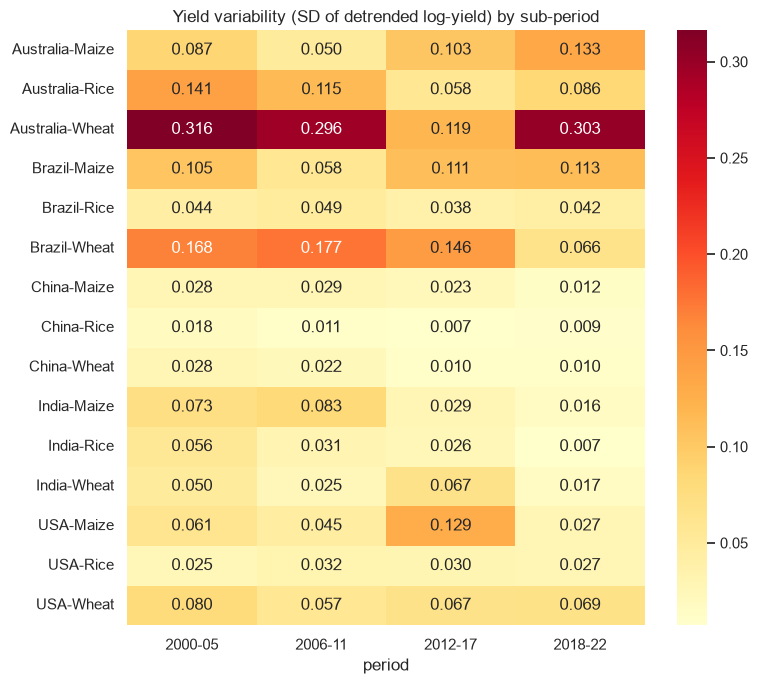

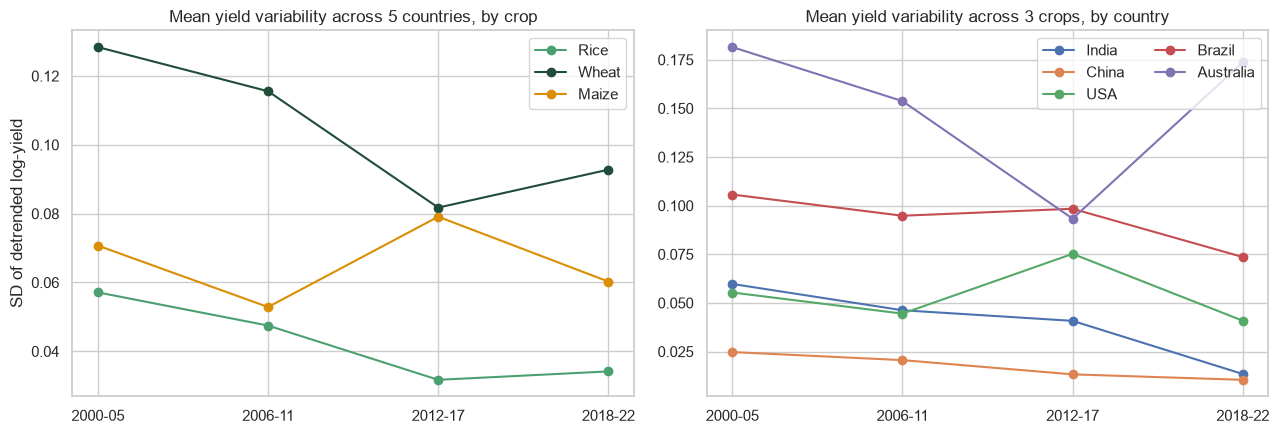

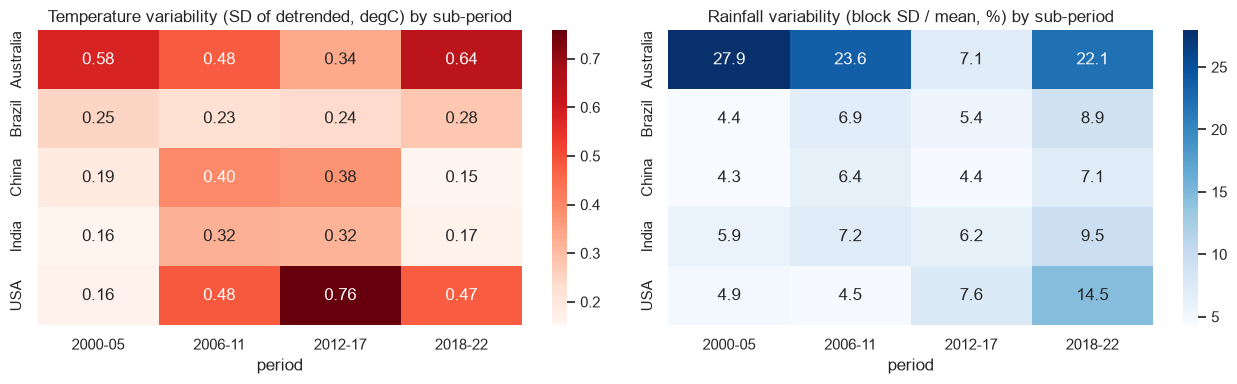

Temperature variability by period


period,2000-05,2006-11,2012-17,2018-22
label,,,,
Australia,0.581,0.478,0.338,0.639
Brazil,0.249,0.226,0.238,0.278
China,0.194,0.397,0.379,0.152
India,0.159,0.323,0.320,0.165
USA,0.161,0.483,0.758,0.474


Rainfall variability (%) by period


period,2000-05,2006-11,2012-17,2018-22
label,,,,
Australia,27.9,23.6,7.1,22.1
Brazil,4.4,6.9,5.4,8.9
China,4.3,6.4,4.4,7.1
India,5.9,7.2,6.2,9.5
USA,4.9,4.5,7.6,14.5


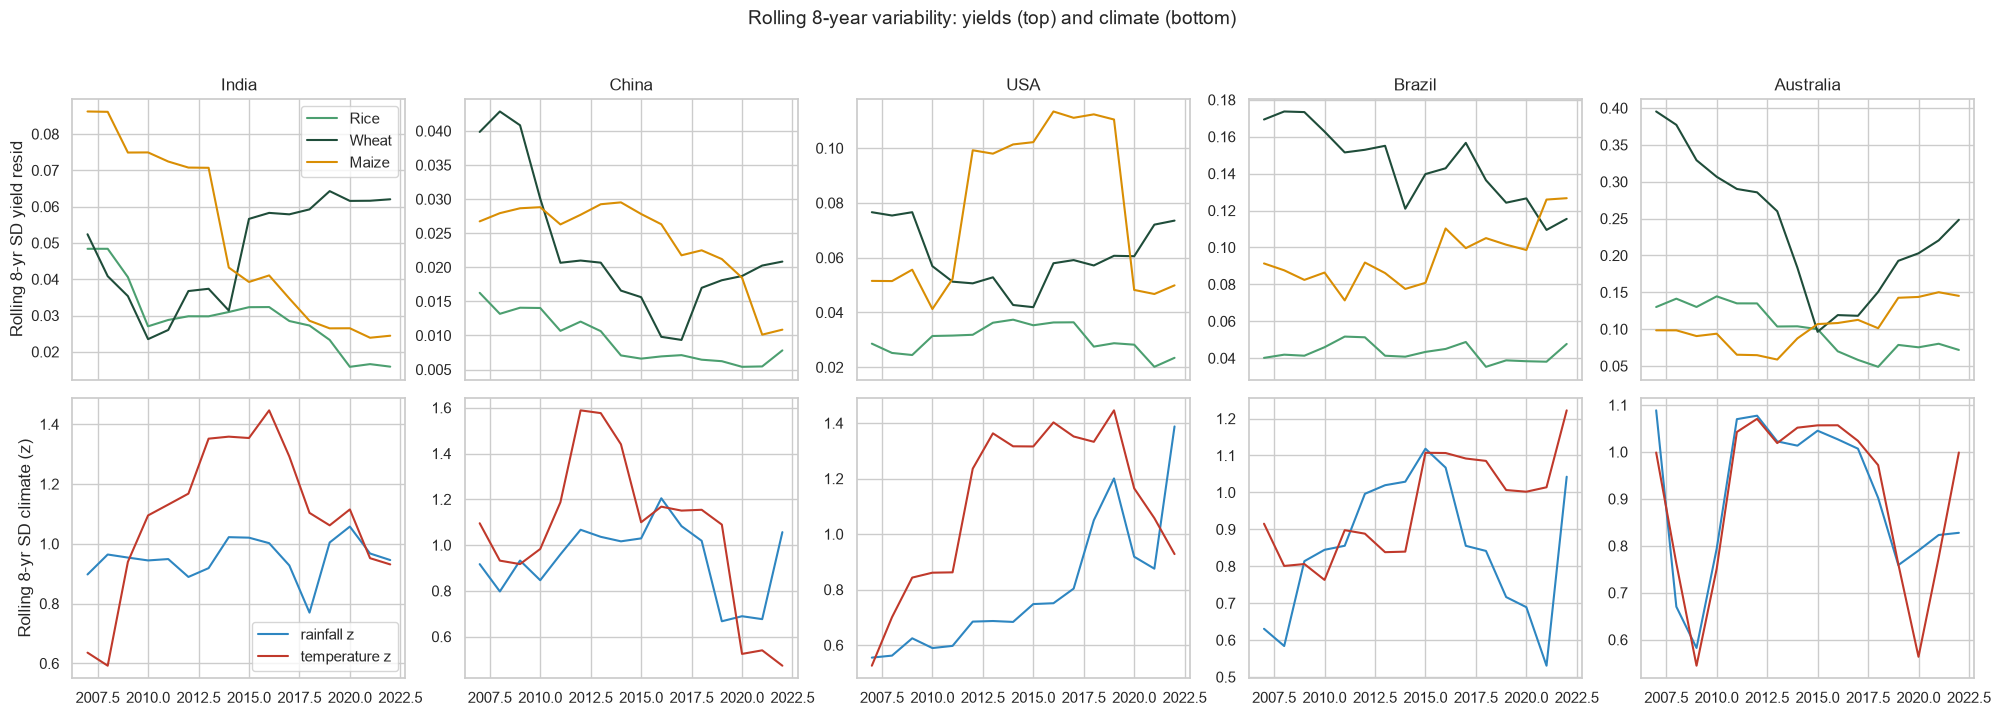

|yield residual| trend: positive in 5 of 15 series; significant (p<0.05) in 2; (p<0.10) in 4


,label,Crop,slope_abs_resid_per_decade,p
0,Australia,Maize,0.0211,0.3127
1,Australia,Rice,-0.0162,0.4195
2,Australia,Wheat,-0.0703,0.1597
3,Brazil,Maize,0.0168,0.3340
4,Brazil,Rice,0.0032,0.6946
5,Brazil,Wheat,-0.0345,0.1461
6,China,Maize,-0.0072,0.0806
7,China,Rice,-0.0037,0.1388
8,China,Wheat,-0.0096,0.0658
9,India,Maize,-0.0323,0.0009


In [9]:
def period_label(y):
    for a,b in PERIODS:
        if a<=y<=b: return f'{a}-{str(b)[2:]}'
panel['period'] = panel.Year.map(period_label); cl2['period'] = cl2.Year.map(period_label)
plabels = [f'{a}-{str(b)[2:]}' for a,b in PERIODS]

# Yield variability per series per period
py = panel.groupby(['label','Crop','period']).ly_res.std(ddof=1).rename('yield_SD').reset_index()
pper = py.pivot_table(index=['label','Crop'], columns='period', values='yield_SD')[plabels]
pper['first_half_mean'] = pper[plabels[:2]].mean(axis=1); pper['second_half_mean'] = pper[plabels[2:]].mean(axis=1)
pper['ratio_2nd_to_1st'] = pper.second_half_mean/pper.first_half_mean
pper.round(3).to_csv(f'{OUT_DIR}/tables/yield_variability_by_period.csv'); display(pper.round(3))
print(f"Series where yield variability rose (2nd half > 1st half): {(pper.ratio_2nd_to_1st>1).sum()} of {len(pper)}")

# heatmap
plt.figure(figsize=(8,7)); sns.heatmap(pper[plabels], annot=True, fmt='.3f', cmap='YlOrRd'); plt.title('Yield variability (SD of detrended log-yield) by sub-period'); plt.ylabel('')
save('10_yield_variability_periods_heatmap')

# crop-average lines
fig, axes = plt.subplots(1,2, figsize=(13,4.5))
m = py.groupby(['Crop','period']).yield_SD.mean().reset_index()
for cr in CROPS:
    d = m[m.Crop==cr].set_index('period').loc[plabels]; axes[0].plot(plabels, d.yield_SD, marker='o', color=CROP_COLORS[cr], label=cr)
axes[0].set_title('Mean yield variability across 5 countries, by crop'); axes[0].legend(); axes[0].set_ylabel('SD of detrended log-yield')
for c in COUNTRIES:
    d = py[py.label==short(c)].groupby('period').yield_SD.mean().loc[plabels]; axes[1].plot(plabels, d, marker='o', label=short(c))
axes[1].set_title('Mean yield variability across 3 crops, by country'); axes[1].legend(ncol=2)
save('11_yield_variability_periods_lines')

# Climate variability per period
cl2['label'] = cl2.Country.map(short)
tv = cl2.groupby(['label','period']).temp_res.std(ddof=1).unstack()[plabels]
rm = cl2.groupby('label').precipitation_mm.mean()
rv = (cl2.groupby(['label','period']).precipitation_mm.std(ddof=1).unstack()[plabels].div(rm, axis=0)*100)
fig, axes = plt.subplots(1,2, figsize=(13,4))
sns.heatmap(tv, annot=True, fmt='.2f', cmap='Reds', ax=axes[0]); axes[0].set_title('Temperature variability (SD of detrended, degC) by sub-period'); axes[0].set_ylabel('')
sns.heatmap(rv, annot=True, fmt='.1f', cmap='Blues', ax=axes[1]); axes[1].set_title('Rainfall variability (block SD / mean, %) by sub-period'); axes[1].set_ylabel('')
save('12_climate_variability_periods')
print('Temperature variability by period'); display(tv.round(3)); print('Rainfall variability (%) by period'); display(rv.round(1))
tv.round(3).to_csv(f'{OUT_DIR}/tables/temp_variability_by_period.csv'); rv.round(2).to_csv(f'{OUT_DIR}/tables/rain_variability_by_period.csv')

# Rolling SD
fig, axes = plt.subplots(2,5, figsize=(20,7), sharex=True)
for j,c in enumerate(COUNTRIES):
    for cr in CROPS:
        d = panel[(panel.Country==c)&(panel.Crop==cr)].sort_values('Year')
        axes[0,j].plot(d.Year, d.ly_res.rolling(ROLL).std(), color=CROP_COLORS[cr], label=cr)
    axes[0,j].set_title(short(c))
    d = cl2[cl2.Country==c].sort_values('Year')
    axes[1,j].plot(d.Year, d.rain_z.rolling(ROLL).std(), color='#2E86C1', label='rainfall z')
    axes[1,j].plot(d.Year, d.temp_z.rolling(ROLL).std(), color='#C0392B', label='temperature z')
axes[0,0].set_ylabel(f'Rolling {ROLL}-yr SD yield resid'); axes[1,0].set_ylabel(f'Rolling {ROLL}-yr SD climate (z)'); axes[0,0].legend(); axes[1,0].legend()
fig.suptitle(f'Rolling {ROLL}-year variability: yields (top) and climate (bottom)', y=1.02, fontsize=14)
save('13_rolling_variability')

# trend in |residual|
tr = []
for (c,cr),g in panel.groupby(['label','Crop']):
    s = stats.linregress(g.Year, g.ly_res.abs()); tr.append(dict(label=c, Crop=cr, slope_abs_resid_per_decade=s.slope*10, p=s.pvalue))
tr = pd.DataFrame(tr); tr.round(4).to_csv(f'{OUT_DIR}/tables/variability_trend_tests.csv', index=False)
print(f"|yield residual| trend: positive in {(tr.slope_abs_resid_per_decade>0).sum()} of 15 series; significant (p<0.05) in {(tr.p<0.05).sum()}; (p<0.10) in {(tr.p<0.10).sum()}")
display(tr.round(4))

## 8. Year-level climate sensitivity (core analysis)
This is the analysis that answers *"which crops are most sensitive to climate variability?"* With ~23 years per series it has far more statistical power than the 15-point cross-country correlation.

**Model (one regression per country-crop):**
`yield_residual_t = a + b_T * TempAnomaly_t(z) + b_R * RainAnomaly_t(z) + error`
- Residual = log deviation from the technology trend; z-scores are per country, so **b is the % change in yield for a 1-SD hotter / wetter year** (coefficient x100).
- **R-squared** = share of year-to-year yield variation explained by climate; it is our sensitivity score.
- Same model is repeated for **production** residuals (the question mentions crop *production*).
- **Pooled model:** all 15 series together, with separate temperature and rainfall slopes per crop (heteroskedasticity-robust SEs) and Wald tests of whether crops differ.

In [10]:
def fit_series(g, target):
    X = sm.add_constant(g[['temp_z','rain_z']]); r = sm.OLS(g[target], X).fit()
    return dict(b_temp_pct=r.params['temp_z']*100, p_temp=r.pvalues['temp_z'], b_rain_pct=r.params['rain_z']*100, p_rain=r.pvalues['rain_z'],
                R2=r.rsquared, adjR2=r.rsquared_adj, F_p=r.f_pvalue, n=int(r.nobs))
sens = {}
for tgt,name in [('ly_res','yield'),('lp_res','production')]:
    t = pd.DataFrame([dict(label=c, Crop=cr, **fit_series(g,tgt)) for (c,cr),g in panel.groupby(['label','Crop'])])
    t['abs_b_temp'], t['abs_b_rain'] = t.b_temp_pct.abs(), t.b_rain_pct.abs(); sens[name]=t
    t.round(4).to_csv(f'{OUT_DIR}/tables/sensitivity_{name}.csv', index=False)
    print(f'--- Per-series regression: {name} residual ~ temperature z + rainfall z ---'); display(t.round(3))

def crop_summary(t):
    return t.groupby('Crop').agg(mean_R2=('R2','mean'), mean_abs_rain_effect_pct=('abs_b_rain','mean'), mean_abs_temp_effect_pct=('abs_b_temp','mean'),
         n_rain_sig_5pct=('p_rain', lambda s:(s<0.05).sum()), n_temp_sig_5pct=('p_temp', lambda s:(s<0.05).sum()), n_model_sig_5pct=('F_p', lambda s:(s<0.05).sum())).sort_values('mean_R2', ascending=False)
for name in sens: print(f'\nCrop sensitivity summary ({name}) - ranked by mean R2'); display(crop_summary(sens[name]).round(3))

--- Per-series regression: yield residual ~ temperature z + rainfall z ---


,label,Crop,b_temp_pct,p_temp,b_rain_pct,p_rain,R2,adjR2,F_p,n,abs_b_temp,abs_b_rain
0,Australia,Maize,1.453,0.736,0.476,0.912,0.010,-0.088,0.900,23,1.453,0.476
1,Australia,Rice,0.056,0.988,3.927,0.307,0.147,0.062,0.204,23,0.056,3.927
2,Australia,Wheat,-4.914,0.595,10.155,0.278,0.289,0.218,0.033,23,4.914,10.155
3,Brazil,Maize,2.590,0.301,-0.191,0.938,0.063,-0.030,0.519,23,2.590,0.191
4,Brazil,Rice,-0.197,0.829,1.763,0.063,0.193,0.113,0.117,23,0.197,1.763
5,Brazil,Wheat,-2.039,0.549,-1.023,0.763,0.019,-0.079,0.828,23,2.039,1.023
6,China,Maize,-0.839,0.119,-0.634,0.233,0.150,0.065,0.196,23,0.839,0.634
7,China,Rice,-0.483,0.061,0.001,0.998,0.170,0.087,0.155,23,0.483,0.001
8,China,Wheat,0.525,0.398,-0.914,0.148,0.153,0.068,0.190,23,0.525,0.914
9,India,Maize,-1.699,0.133,1.864,0.101,0.229,0.152,0.074,23,1.699,1.864


--- Per-series regression: production residual ~ temperature z + rainfall z ---


,label,Crop,b_temp_pct,p_temp,b_rain_pct,p_rain,R2,adjR2,F_p,n,abs_b_temp,abs_b_rain
0,Australia,Maize,-3.518,0.629,-6.869,0.349,0.057,-0.037,0.554,23,3.518,6.869
1,Australia,Rice,-45.697,0.326,-24.083,0.601,0.062,-0.032,0.529,23,45.697,24.083
2,Australia,Wheat,-5.563,0.594,14.200,0.182,0.357,0.292,0.012,23,5.563,14.200
3,Brazil,Maize,-0.574,0.845,-2.660,0.369,0.041,-0.055,0.656,23,0.574,2.660
4,Brazil,Rice,-0.667,0.708,3.549,0.057,0.213,0.134,0.091,23,0.667,3.549
5,Brazil,Wheat,-2.135,0.748,-4.798,0.473,0.026,-0.071,0.766,23,2.135,4.798
6,China,Maize,-0.284,0.852,0.666,0.662,0.013,-0.085,0.873,23,0.284,0.666
7,China,Rice,-1.378,0.104,0.097,0.906,0.134,0.047,0.238,23,1.378,0.097
8,China,Wheat,-0.225,0.842,-0.211,0.851,0.003,-0.096,0.968,23,0.225,0.211
9,India,Maize,-1.105,0.381,2.594,0.048,0.219,0.141,0.084,23,1.105,2.594



Crop sensitivity summary (yield) - ranked by mean R2


,mean_R2,mean_abs_rain_effect_pct,mean_abs_temp_effect_pct,n_rain_sig_5pct,n_temp_sig_5pct,n_model_sig_5pct
Crop,,,,,,
Rice,0.164,1.402,0.491,0,1,1
Maize,0.143,1.238,1.611,1,0,1
Wheat,0.137,2.919,1.921,0,0,1



Crop sensitivity summary (production) - ranked by mean R2


,mean_R2,mean_abs_rain_effect_pct,mean_abs_temp_effect_pct,n_rain_sig_5pct,n_temp_sig_5pct,n_model_sig_5pct
Crop,,,,,,
Rice,0.176,6.339,10.271,0,1,1
Wheat,0.120,4.386,2.241,0,0,1
Maize,0.097,3.121,1.323,1,0,0


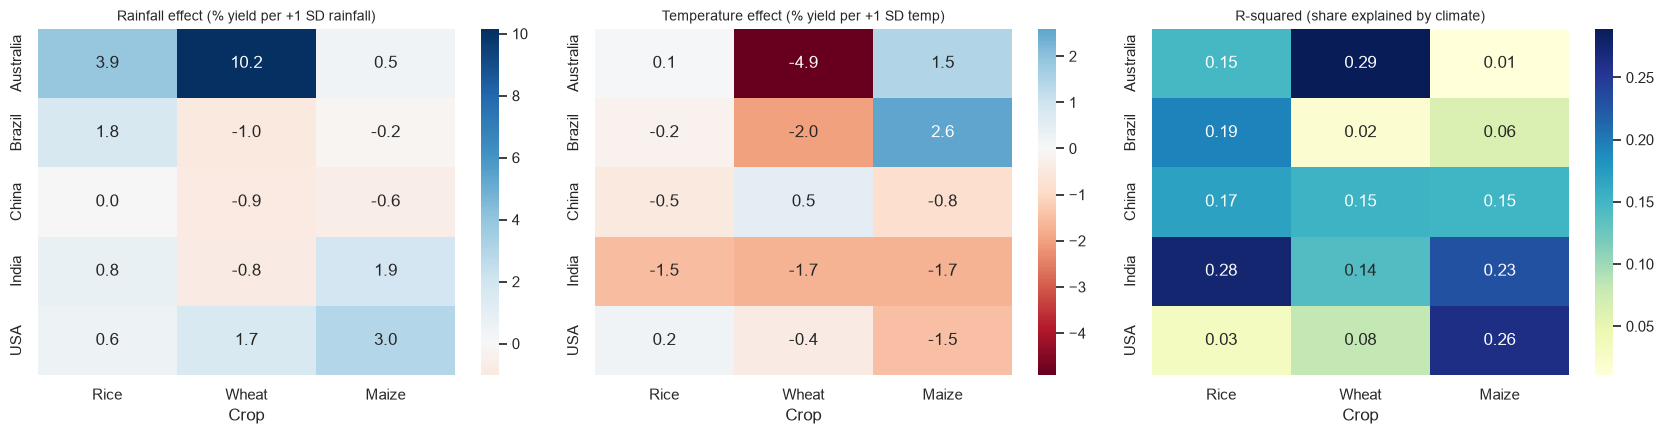

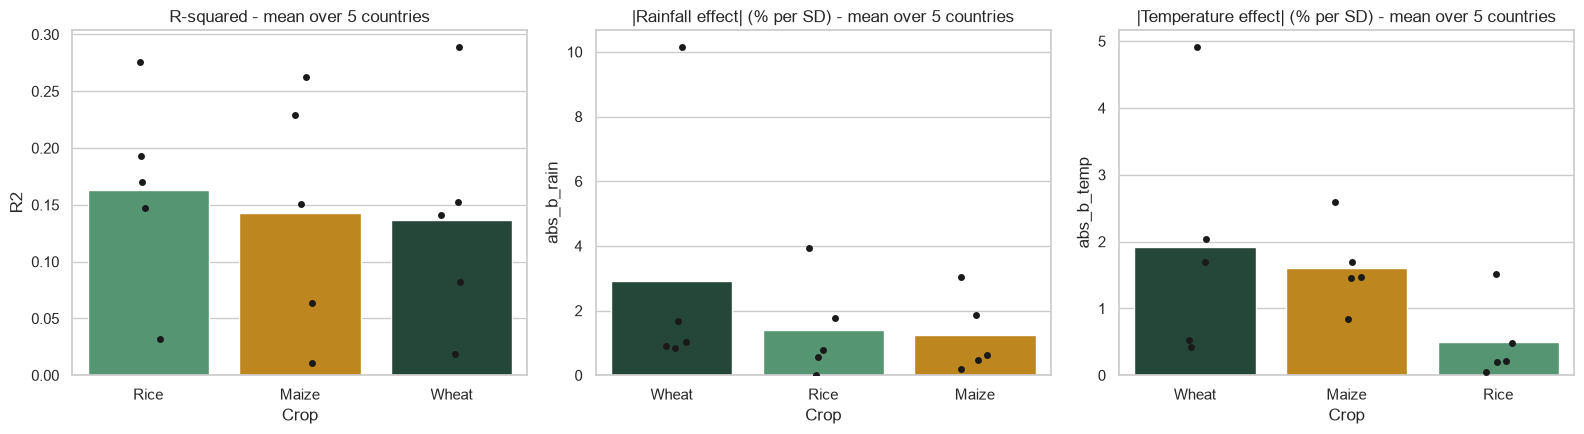

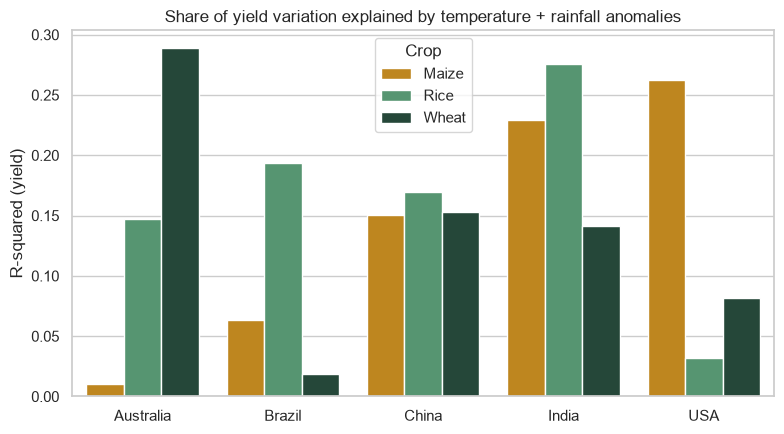

Pooled model (all 15 series; % yield change per +1 SD anomaly)


,coef_pct,ci_low,ci_high,p
temp_z:C(Crop)[Maize],-0.022,-1.715,1.671,0.979
temp_z:C(Crop)[Rice],-0.800,-1.799,0.198,0.116
temp_z:C(Crop)[Wheat],-2.723,-5.007,-0.440,0.019
rain_z:C(Crop)[Maize],0.624,-0.861,2.109,0.410
rain_z:C(Crop)[Rice],1.163,0.373,1.953,0.004
rain_z:C(Crop)[Wheat],1.862,-0.232,3.956,0.081


Wald test - do crops differ in their temperature slope?  p = 0.173
Wald test - do crops differ in their rainfall slope?  p = 0.630


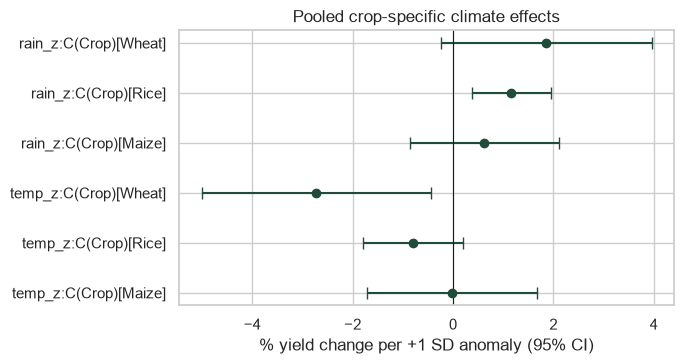

In [11]:
sy = sens['yield']
# heatmaps of effects
fig, axes = plt.subplots(1,3, figsize=(17,4.5))
for ax,col,t,cm in zip(axes, ['b_rain_pct','b_temp_pct','R2'], ['Rainfall effect (% yield per +1 SD rainfall)','Temperature effect (% yield per +1 SD temp)','R-squared (share explained by climate)'], ['RdBu','RdBu','YlGnBu']):
    pv = sy.pivot(index='label', columns='Crop', values=col)[CROPS]
    kw = dict(center=0) if cm=='RdBu' else {}
    sns.heatmap(pv, annot=True, fmt='.2f' if col=='R2' else '.1f', cmap=cm, ax=ax, **kw); ax.set_title(t, fontsize=10); ax.set_ylabel('')
save('14_sensitivity_heatmaps')

# crop sensitivity bars
fig, axes = plt.subplots(1,3, figsize=(16,4.5))
for ax,col,t in zip(axes, ['R2','abs_b_rain','abs_b_temp'], ['R-squared','|Rainfall effect| (% per SD)','|Temperature effect| (% per SD)']):
    order = sy.groupby('Crop')[col].mean().sort_values(ascending=False).index
    sns.barplot(data=sy, x='Crop', y=col, order=order, errorbar=None, palette=CROP_COLORS, ax=ax); sns.stripplot(data=sy, x='Crop', y=col, order=order, color='k', ax=ax); ax.set_title(t+' - mean over 5 countries')
save('15_crop_sensitivity')

# country comparison
fig, ax = plt.subplots(figsize=(8,4.5)); sns.barplot(data=sy, x='label', y='R2', hue='Crop', palette=CROP_COLORS, ax=ax); ax.set_xlabel(''); ax.set_ylabel('R-squared (yield)'); ax.set_title('Share of yield variation explained by temperature + rainfall anomalies')
save('16_r2_by_country')

# Pooled model with crop-specific slopes
pool = smf.ols('ly_res ~ 0 + temp_z:C(Crop) + rain_z:C(Crop)', data=panel).fit(cov_type='HC1')
pt = pd.DataFrame({'coef_pct':pool.params*100, 'ci_low':pool.conf_int()[0]*100, 'ci_high':pool.conf_int()[1]*100, 'p':pool.pvalues}).round(3)
print('Pooled model (all 15 series; % yield change per +1 SD anomaly)'); display(pt); pt.to_csv(f'{OUT_DIR}/tables/pooled_model.csv')
n = list(pool.params.index); g = lambda v,c: [x for x in n if x.startswith(v) and f'[{c}]' in x][0]
for v,lab in [('temp_z','temperature'),('rain_z','rainfall')]:
    w = pool.wald_test(f'{g(v,"Rice")} = {g(v,"Wheat")} = {g(v,"Maize")}', scalar=True)
    print(f'Wald test - do crops differ in their {lab} slope?  p = {float(w.pvalue):.3f}')
fig, ax = plt.subplots(figsize=(7,3.8)); yp = np.arange(len(pt))
ax.errorbar(pt.coef_pct, yp, xerr=[pt.coef_pct-pt.ci_low, pt.ci_high-pt.coef_pct], fmt='o', color='#1F4D3A', capsize=4)
ax.set_yticks(yp); ax.set_yticklabels(pt.index); ax.axvline(0,color='k',lw=0.8); ax.set_xlabel('% yield change per +1 SD anomaly (95% CI)'); ax.set_title('Pooled crop-specific climate effects')
save('17_pooled_effects')

## 9. Step 7 - Extreme years
Do the worst yield years coincide with climate extremes? 
- **Bad year** = yield residual at least 1 SD below the series' own trend.
- **Climate extreme** = rainfall or temperature anomaly with |z| >= 1 in that country-year; we also separate *dry* (rain z <= -1), *wet* (z >= 1), and *hot* (temp z >= 1) years.
- We compare the share of climate-extreme years among bad yield years versus among all other years (Fisher exact test).

Bad yield years: 53 of 345 series-years


,climate_flag,pct_of_bad_years,pct_of_other_years,odds_ratio,fisher_p
0,clim_extreme,49.057,43.493,1.251,0.457
1,dry,24.528,6.849,4.420,0.000
2,wet,7.547,18.151,0.368,0.069
3,hot,26.415,13.699,2.262,0.024


20 worst yield shocks (deviation from trend) with that year's climate anomaly


,label,Crop,Year,Yield,dev_pct,yield_z,rain_z,temp_z
52,Australia,Wheat,2006,917.3,-43.10,-2.09,-0.18,0.08
48,Australia,Wheat,2002,907.0,-38.04,-1.78,-1.57,1.07
53,Australia,Wheat,2007,1078.8,-34.68,-1.58,0.21,0.32
65,Australia,Wheat,2019,1468.1,-33.44,-1.51,-2.12,1.67
28,Australia,Rice,2005,6616.8,-23.74,-2.68,-0.97,1.46
121,Brazil,Wheat,2006,1592.7,-22.34,-1.79,0.48,-0.33
288,USA,Maize,2012,7727.0,-22.32,-3.48,-1.52,2.37
19,Australia,Maize,2019,5550.7,-21.72,-2.30,-2.12,1.67
64,Australia,Wheat,2018,1691.7,-21.43,-0.89,-0.85,0.61
117,Brazil,Wheat,2002,1475.4,-20.87,-1.65,-0.32,1.37


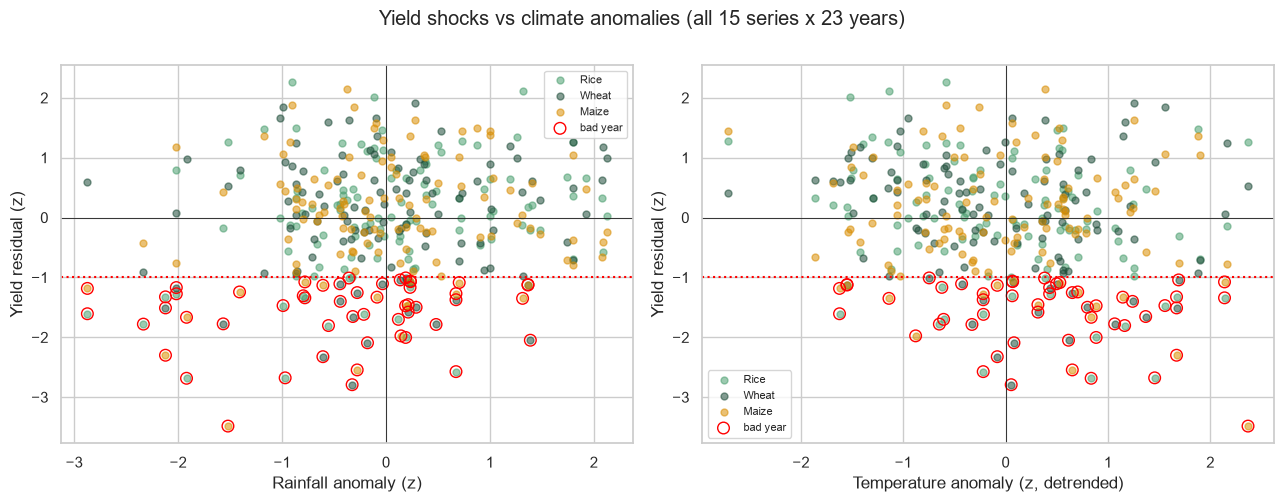

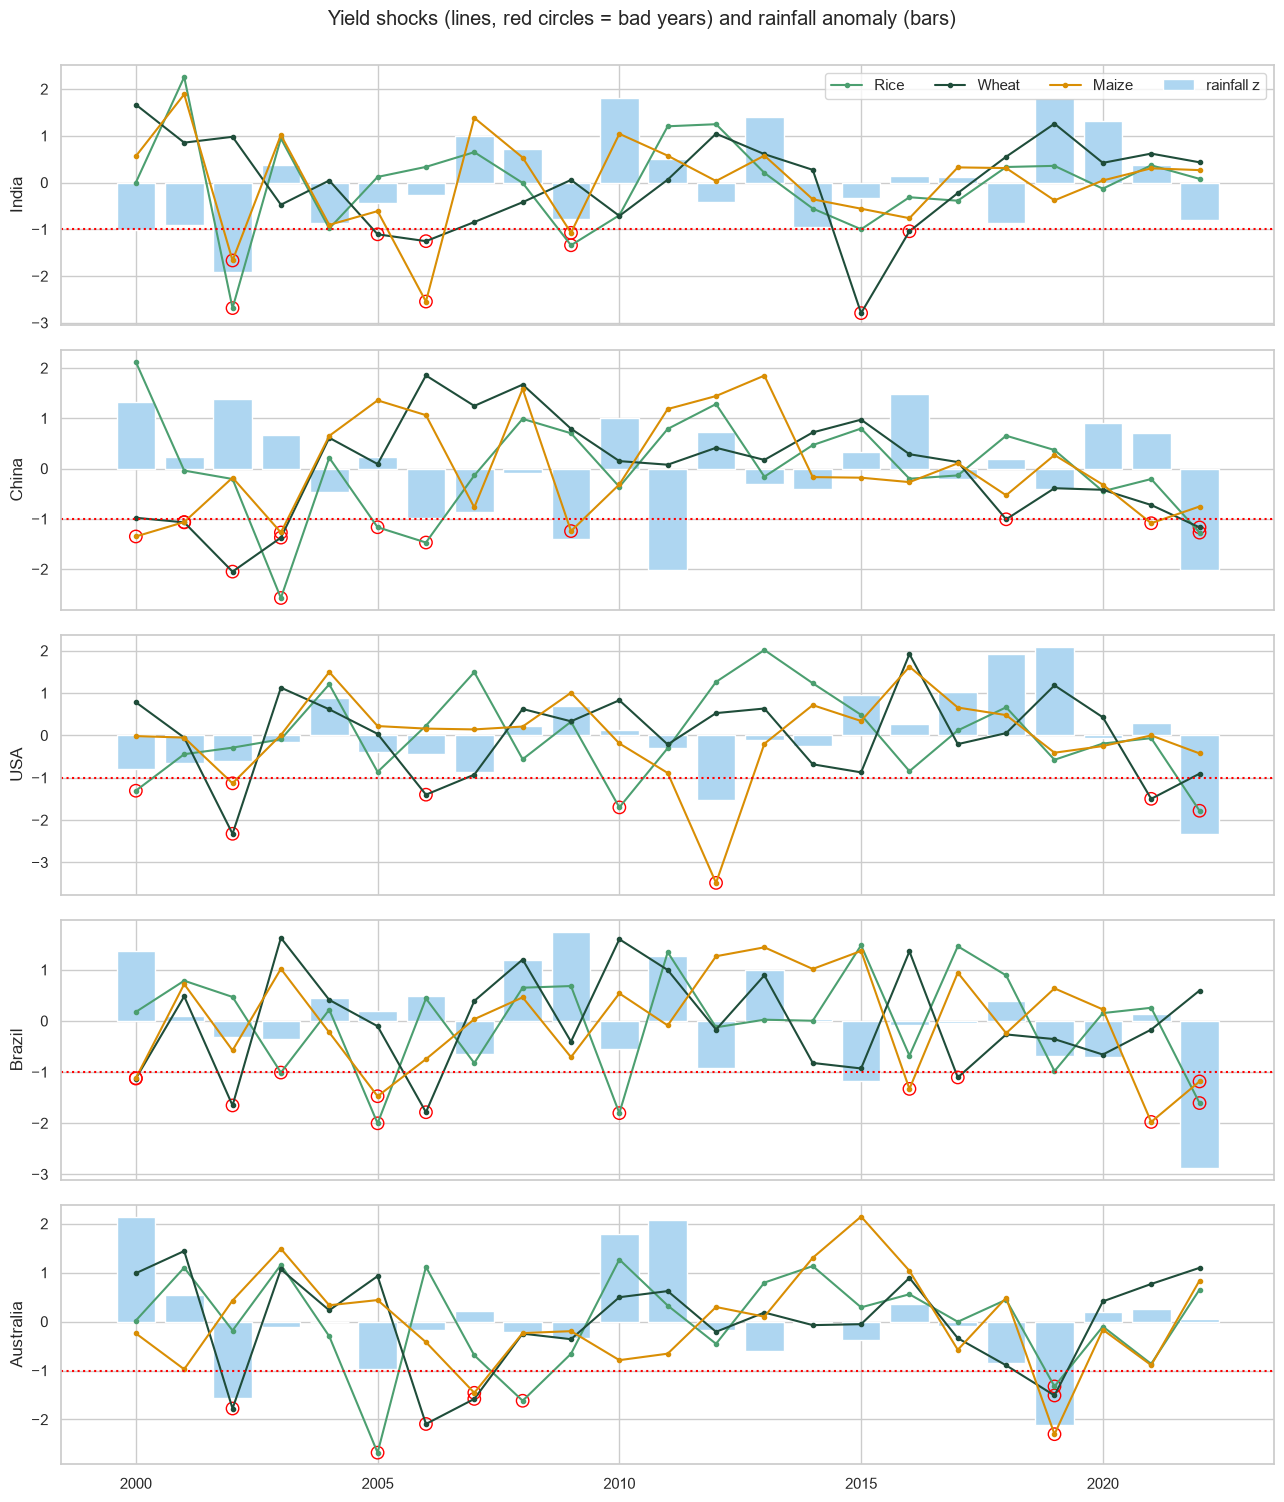

In [12]:
panel['yield_z'] = panel.groupby(['label','Crop']).ly_res.transform(lambda s:s/s.std(ddof=1))
panel['dev_pct'] = (np.exp(panel.ly_res)-1)*100
panel['bad'] = panel.yield_z<=-1
panel['dry'], panel['wet'], panel['hot'] = panel.rain_z<=-1, panel.rain_z>=1, panel.temp_z>=1
panel['clim_extreme'] = (panel.rain_z.abs()>=1)|(panel.temp_z.abs()>=1)
rows=[]
for flag in ['clim_extreme','dry','wet','hot']:
    a = pd.crosstab(panel.bad, panel[flag]).reindex(index=[True,False], columns=[True,False], fill_value=0)
    odds,p = stats.fisher_exact(a.values)
    rows.append(dict(climate_flag=flag, pct_of_bad_years=a.loc[True,True]/a.loc[True].sum()*100, pct_of_other_years=a.loc[False,True]/a.loc[False].sum()*100, odds_ratio=odds, fisher_p=p))
ev = pd.DataFrame(rows).round(3); ev.to_csv(f'{OUT_DIR}/tables/extreme_year_tests.csv', index=False)
print(f'Bad yield years: {panel.bad.sum()} of {len(panel)} series-years'); display(ev)

worst = panel.sort_values('ly_res').head(20)[['label','Crop','Year','Yield','dev_pct','yield_z','rain_z','temp_z']].round(2)
worst.to_csv(f'{OUT_DIR}/tables/worst_20_yield_years.csv', index=False); print('20 worst yield shocks (deviation from trend) with that year\'s climate anomaly'); display(worst)

fig, axes = plt.subplots(1,2, figsize=(13,5))
for ax,col,xl in zip(axes, ['rain_z','temp_z'], ['Rainfall anomaly (z)','Temperature anomaly (z, detrended)']):
    for cr in CROPS:
        d = panel[panel.Crop==cr]; ax.scatter(d[col], d.yield_z, s=25, alpha=0.55, color=CROP_COLORS[cr], label=cr)
    d = panel[panel.bad]; ax.scatter(d[col], d.yield_z, s=70, facecolors='none', edgecolors='red', label='bad year')
    ax.axhline(-1, color='red', ls=':'); ax.axhline(0,color='k',lw=0.6); ax.axvline(0,color='k',lw=0.6); ax.set_xlabel(xl); ax.set_ylabel('Yield residual (z)'); ax.legend(fontsize=8)
fig.suptitle('Yield shocks vs climate anomalies (all 15 series x 23 years)', y=1.0)
save('18_extreme_scatter')

fig, axes = plt.subplots(5,1, figsize=(13,15), sharex=True)
for ax,c in zip(axes, COUNTRIES):
    d = cl2[cl2.Country==c]; ax.bar(d.Year, d.rain_z, color='#AED6F1', label='rainfall z')
    for cr in CROPS:
        e = panel[(panel.Country==c)&(panel.Crop==cr)]; ax.plot(e.Year, e.yield_z, marker='o', ms=3, color=CROP_COLORS[cr], label=cr)
        b = e[e.bad]; ax.scatter(b.Year, b.yield_z, s=80, facecolors='none', edgecolors='red')
    ax.axhline(-1, color='red', ls=':'); ax.set_ylabel(short(c)); 
axes[0].legend(ncol=4); fig.suptitle('Yield shocks (lines, red circles = bad years) and rainfall anomaly (bars)', y=1.0)
save('19_extreme_timelines')

## 10. Step 8 - Climate-region comparison
The question asks to compare *agro-climatic regions*. With national data we classify each country by its own mean climate (computed above) using transparent rules:
- **Arid/semi-arid:** mean annual rainfall < 600 mm
- **Tropical/monsoon:** otherwise, mean temperature >= 20 degC
- **Temperate/continental:** everything else

Then we compare instability and climate sensitivity across region x crop. With only 5 countries each region has 1-2 members, so this is **descriptive**; sub-national zones are the natural refinement.

,label,mean_temp_C,mean_rain_mm,rain_CV_%,Region
0,Australia,22.4,446.9,21.8,Arid / semi-arid
1,Brazil,24.8,1753.5,6.9,Tropical / monsoon
2,China,6.9,786.2,6.0,Temperate / continental
3,India,23.5,1260.8,7.8,Tropical / monsoon
4,USA,12.0,793.3,8.1,Temperate / continental


yield_instability     R2  abs_rain_effect_pct  abs_temp_effect_pct      countries
Region                  Crop                                                                                    
Arid / semi-arid        Maize              0.106  0.010                0.476                1.453      Australia
                        Rice               0.101  0.147                3.927                0.056      Australia
                        Wheat              0.270  0.289               10.155                4.914      Australia
Temperate / continental Maize              0.049  0.206                1.830                1.156     China, USA
                        Rice               0.021  0.101                0.275                0.347     China, USA
                        Wheat              0.047  0.117                1.294                0.477     China, USA
Tropical / monsoon      Maize              0.080  0.146                1.028                2.145  Brazil, India
                        Rice               0.038  0.234                1.266                0.853  Brazil, India
                        Wheat              0.095  0.080                0.926                1.868  Brazil, India

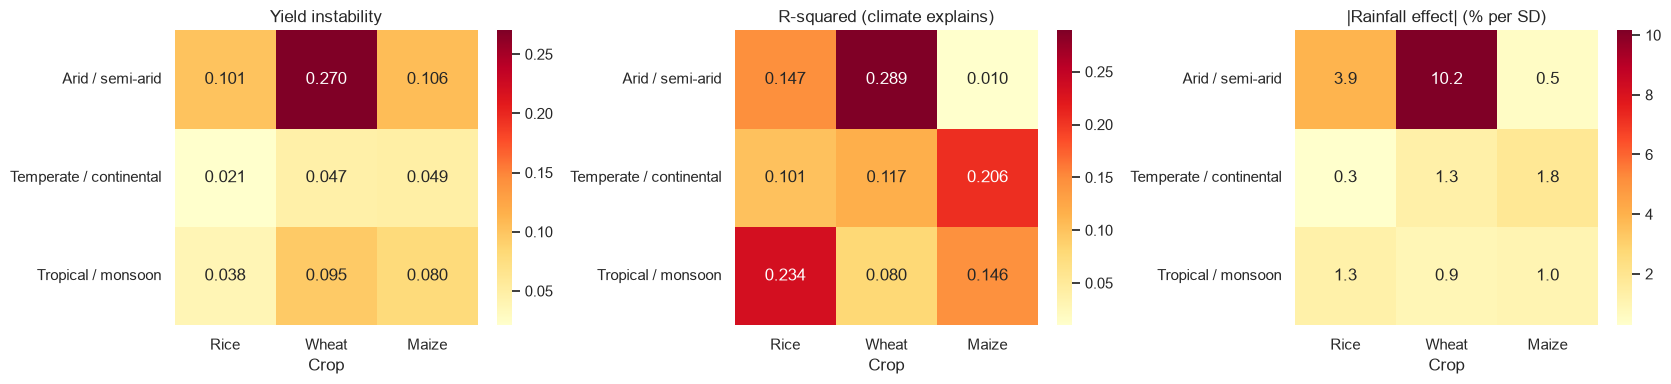

In [13]:
def region(r):
    if r.mean_rain_mm < 600: return 'Arid / semi-arid'
    return 'Tropical / monsoon' if r.mean_temp_C >= 20 else 'Temperate / continental'
clim_var['Region'] = clim_var.apply(region, axis=1)
display(clim_var[['label','mean_temp_C','mean_rain_mm','rain_CV_%','Region']].round(1))
rg = inst.merge(clim_var[['Country','Region']], on='Country').merge(sens['yield'][['label','Crop','R2','b_rain_pct','b_temp_pct','abs_b_rain','abs_b_temp']], on=['label','Crop'])
reg_tab = rg.groupby(['Region','Crop']).agg(yield_instability=('yield_instability','mean'), R2=('R2','mean'), abs_rain_effect_pct=('abs_b_rain','mean'), abs_temp_effect_pct=('abs_b_temp','mean'), countries=('label', lambda s:', '.join(sorted(set(s))))).round(3)
reg_tab.to_csv(f'{OUT_DIR}/tables/region_comparison.csv'); display(reg_tab)
fig, axes = plt.subplots(1,3, figsize=(17,4))
for ax,col,t in zip(axes, ['yield_instability','R2','abs_rain_effect_pct'], ['Yield instability','R-squared (climate explains)','|Rainfall effect| (% per SD)']):
    sns.heatmap(reg_tab.reset_index().pivot(index='Region', columns='Crop', values=col)[CROPS], annot=True, fmt='.3f' if col!='abs_rain_effect_pct' else '.1f', cmap='YlOrRd', ax=ax); ax.set_title(t); ax.set_ylabel('')
save('20_region_comparison')

## 11. Summary of findings (auto-generated from the results above)

In [14]:
cs_y = crop_summary(sens['yield'])
print('1. CLIMATE: temperature trends (degC/decade, 2000-2022):', clim_var.set_index('label').temp_trend_C_per_decade.round(2).to_dict())
print('   Rainfall CV (%):', clim_var.set_index('label')['rain_CV_%'].round(1).to_dict())
print('2. INSTABILITY: crops from least to most unstable (yield):', list(crop_rank.index), crop_rank.yield_instability.round(3).tolist())
mx = inst.loc[inst.yield_instability.idxmax()]; mn = inst.loc[inst.yield_instability.idxmin()]
print(f'   Most unstable: {mx.label} {mx.Crop} ({mx.yield_instability:.3f}); most stable: {mn.label} {mn.Crop} ({mn.yield_instability:.3f})')
r = corr_tab[(corr_tab.climate=='rain_CV_%')&(corr_tab['sample'].str.startswith('All'))].iloc[0]; r2 = corr_tab[(corr_tab.climate=='rain_CV_%')&(corr_tab['sample'].str.startswith('Excl'))].iloc[0]
t1 = corr_tab[(corr_tab.climate=='temp_SD_detrended')&(corr_tab['sample'].str.startswith('All'))].iloc[0]
print(f'3. CROSS-COUNTRY: rainfall CV vs yield instability r={r.pearson_r:.2f} (rho={r.spearman_rho:.2f}); without Australia r={r2.pearson_r:.2f}; temperature SD r={t1.pearson_r:.2f}')
print(f'4. INCREASING VARIABILITY: yield variability higher in 2nd half than 1st in {(pper.ratio_2nd_to_1st>1).sum()} of 15 series; |residual| trend positive in {(tr.slope_abs_resid_per_decade>0).sum()} of 15, significant in {(tr.p<0.05).sum()}')
print('5. SENSITIVITY (yield): crops ranked by mean R2:', cs_y.mean_R2.round(2).to_dict())
print('   mean |rain effect| %/SD:', cs_y.mean_abs_rain_effect_pct.round(1).to_dict(), '| mean |temp effect| %/SD:', cs_y.mean_abs_temp_effect_pct.round(1).to_dict())
print(f"6. EXTREME YEARS: {ev.set_index('climate_flag').loc['clim_extreme','pct_of_bad_years']:.0f}% of bad yield years coincide with a rainfall/temperature extreme vs {ev.set_index('climate_flag').loc['clim_extreme','pct_of_other_years']:.0f}% of other years")
print('7. REGIONS:'); display(reg_tab[['yield_instability','R2']])

1. CLIMATE: temperature trends (degC/decade, 2000-2022): {'Australia': 0.33, 'Brazil': 0.3, 'China': 0.33, 'India': 0.02, 'USA': 0.3}
   Rainfall CV (%): {'Australia': 21.8, 'Brazil': 6.9, 'China': 6.0, 'India': 7.8, 'USA': 8.1}
2. INSTABILITY: crops from least to most unstable (yield): ['Rice', 'Maize', 'Wheat'] [0.044, 0.073, 0.111]
   Most unstable: Australia Wheat (0.270); most stable: China Rice (0.012)
3. CROSS-COUNTRY: rainfall CV vs yield instability r=0.67 (rho=0.62); without Australia r=0.18; temperature SD r=0.34
4. INCREASING VARIABILITY: yield variability higher in 2nd half than 1st in 4 of 15 series; |residual| trend positive in 5 of 15, significant in 2
5. SENSITIVITY (yield): crops ranked by mean R2: {'Rice': 0.16, 'Maize': 0.14, 'Wheat': 0.14}
   mean |rain effect| %/SD: {'Rice': 1.4, 'Maize': 1.2, 'Wheat': 2.9} | mean |temp effect| %/SD: {'Rice': 0.5, 'Maize': 1.6, 'Wheat': 1.9}
6. EXTREME YEARS: 49% of bad yield years coincide with a rainfall/temperature extreme vs 4

yield_instability     R2
Region                  Crop                           
Arid / semi-arid        Maize              0.106  0.010
                        Rice               0.101  0.147
                        Wheat              0.270  0.289
Temperate / continental Maize              0.049  0.206
                        Rice               0.021  0.101
                        Wheat              0.047  0.117
Tropical / monsoon      Maize              0.080  0.146
                        Rice               0.038  0.234
                        Wheat              0.095  0.080

## 12. Limitations (say these yourself before you are asked)
- **Spatial scale:** national averages hide regional heterogeneity (irrigated vs rainfed areas); ERA5 averages include non-cropland unless a cropland mask is applied.
- **Small sample:** ~23 years per series and 5 countries; coefficients are noisy and many individual regressions will not be significant. Sub-period SDs use only 5-6 years.
- **ERA5 2023 artefact** excluded; CHIRPS was used only to cross-check India.
- **Annual climate** may miss growing-season timing; SPEI and growing-season indices are the natural next step.
- **Association, not causation:** irrigation, policy, prices, pests and area decisions also drive instability.
- Some country-crop combinations have tiny area (e.g. Australian rice, maize), which makes them volatile for non-climate reasons.